# 02 · Sumativa 1 — Análisis exploratorio e inferencial

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello · Grupo 8

**Dataset:** *Predict Students' Dropout and Academic Success* (UCI, 2021).

Este cuaderno reproduce todas las tablas y figuras del informe de la Sumativa 1 (figuras en
`docs/figuras/sumativa1/`). Sigue el orden del informe:

1. Preparación y carga de datos (calidad de la información)
2. Análisis exploratorio: variables numéricas, categóricas y análisis bivariado
3. Estimación de parámetros (intervalos de confianza al 95 %)
4. Pruebas de hipótesis (con verificación de supuestos)

Requisito: haber ejecutado una vez `00_generacion_faltantes.ipynb`.

## 1. Preparación y carga de datos

**Decisiones del proyecto** (definidas en la Fase 1 y documentadas en `data/README.md`):

- Variable objetivo binaria: **1 = Dropout**, **0 = Graduate**. Se excluyen los estudiantes *Enrolled*, cuyo
  desenlace todavía no se conoce (apunte de bases de datos, sección 3.8).
- Se trabaja con la versión del dataset con faltantes generados al azar (MCAR, 12 % en `Admission grade` y
  `Age at enrollment`, semilla 42), tal como exige el apunte para conjuntos completos.

In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SEMILLA = 42
ALFA = 0.05
OBJETIVO = 'Deserta'
FIG = '../docs/figuras/sumativa1'
os.makedirs(FIG, exist_ok=True)

raw = pd.read_csv('../data/raw/data.csv', sep=';')
df_completo = pd.read_csv('../data/processed/data_con_faltantes.csv')

print('Archivo original      :', raw.shape, '| faltantes:', raw.isna().sum().sum())
print('Versión con faltantes :', df_completo.shape)
print('Tipos de datos leídos por pandas:'); print(raw.dtypes.value_counts())

Archivo original      : (4424, 37) | faltantes: 0
Versión con faltantes : (4424, 38)
Tipos de datos leídos por pandas:
int64      29
float64     7
str         1
Name: count, dtype: int64


In [2]:
df = df_completo[df_completo['Target'].isin(['Dropout', 'Graduate'])].copy()
df[OBJETIVO] = (df['Target'] == 'Dropout').astype(int)
n = len(df)
print(df_completo['Target'].value_counts().to_string(), '\n')
print(f'Estudiantes analizados: {n:,}  |  desertores: {df[OBJETIVO].sum():,} ({df[OBJETIVO].mean()*100:.1f}%)')

Target
Graduate    2209
Dropout     1421
Enrolled     794 

Estudiantes analizados: 3,630  |  desertores: 1,421 (39.1%)


### Estudiantes sin actividad académica registrada
Hay estudiantes con **cero unidades inscritas, acreditadas y evaluadas en ambos semestres**. Entre ellos figuran
estudiantes *Graduate*, lo que es imposible (no se puede titular sin inscribir ninguna unidad): son registros con la
información académica incompleta. Como atenúan todas las comparaciones académicas, se excluyen del análisis en ambas
clases y la decisión queda documentada.

In [3]:
cols_actividad = [f'Curricular units {s} sem ({t})' for s in ['1st', '2nd'] for t in ['enrolled', 'credited', 'evaluations']]
sin_actividad = (df[cols_actividad] == 0).all(axis=1)
n_sin_actividad = int(sin_actividad.sum())
print(f'Sin unidades inscritas, acreditadas ni evaluadas en ambos semestres: {n_sin_actividad}')
print(df.loc[sin_actividad, 'Target'].value_counts().to_string())
print(f"(en el dataset completo, incluidos Enrolled: {(df_completo[cols_actividad] == 0).all(axis=1).sum()})")

df = df[~sin_actividad].copy()
n = len(df)
print(f'\nEstudiantes analizados: {n:,}  |  desertores: {df[OBJETIVO].sum():,} ({df[OBJETIVO].mean()*100:.1f}%)')

Sin unidades inscritas, acreditadas ni evaluadas en ambos semestres: 152
Target
Dropout     77
Graduate    75
(en el dataset completo, incluidos Enrolled: 180)

Estudiantes analizados: 3,478  |  desertores: 1,344 (38.6%)


### 1.1 Tipos de variables

In [4]:
continuas = ['Admission grade', 'Previous qualification (grade)',
             'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
             'Unemployment rate', 'Inflation rate', 'GDP']
discretas = ['Age at enrollment'] + [c for c in df.columns if c.startswith('Curricular units') and '(grade)' not in c]
binarias  = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
             'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
ordinales = ['Application order']
nominales = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
tipos = pd.Series({**{c: 'Cuantitativa continua' for c in continuas}, **{c: 'Cuantitativa discreta' for c in discretas},
                   **{c: 'Cualitativa binaria' for c in binarias}, **{c: 'Cualitativa ordinal' for c in ordinales},
                   **{c: 'Cualitativa nominal' for c in nominales}})
print('Variables clasificadas:', len(tipos))
tipos.value_counts()

Variables clasificadas: 36


Cuantitativa discreta    11
Cualitativa nominal       9
Cualitativa binaria       8
Cuantitativa continua     7
Cualitativa ordinal       1
Name: count, dtype: int64

### 1.2 Reporte de calidad de datos

In [5]:
calidad = {
    'Sin actividad académica (excluidos)': n_sin_actividad,
    'Filas duplicadas': df.drop(columns='id_estudiante').duplicated().sum(),
    'Faltantes Admission grade': df['Admission grade'].isna().sum(),
    'Faltantes Age at enrollment': df['Age at enrollment'].isna().sum(),
    'Filas con al menos un faltante': df[['Admission grade', 'Age at enrollment']].isna().any(axis=1).sum(),
    'Nota 1.er sem = 0': (df['Curricular units 1st sem (grade)'] == 0).sum(),
    'Nota 2.º sem = 0': (df['Curricular units 2nd sem (grade)'] == 0).sum(),
    'Edad fuera de 17-70': (~df['Age at enrollment'].dropna().between(17, 70)).sum(),
    'Nota de admisión fuera de 95-190': (~df['Admission grade'].dropna().between(95, 190)).sum(),
}
reporte = pd.DataFrame({'Casos': calidad})
reporte['%'] = (reporte['Casos'] / n * 100).round(2)                       # % sobre los estudiantes analizados
reporte.loc['Sin actividad académica (excluidos)', '%'] = round(n_sin_actividad / (n + n_sin_actividad) * 100, 2)
reporte

,Casos,%
Sin actividad académica (excluidos),152,4.19
Filas duplicadas,0,0.00
Faltantes Admission grade,437,12.56
Faltantes Age at enrollment,406,11.67
Filas con al menos un faltante,797,22.92
Nota 1.er sem = 0,495,14.23
Nota 2.º sem = 0,650,18.69
Edad fuera de 17-70,0,0.00
Nota de admisión fuera de 95-190,0,0.00


In [6]:
# La nota 0 coincide siempre con 0 unidades aprobadas: no es una nota real
for sem in ['1st', '2nd']:
    nota, aprob = f'Curricular units {sem} sem (grade)', f'Curricular units {sem} sem (approved)'
    print(f"{sem}: coincide nota=0 con aprobadas=0 -> {((df[nota] == 0) == (df[aprob] == 0)).all()}; "
          f"menor nota positiva = {df.loc[df[nota] > 0, nota].min()}")
    df[nota + ' sin ceros'] = df[nota].where(df[nota] > 0)       # limpieza básica: 0 -> sin nota

1st: coincide nota=0 con aprobadas=0 -> True; menor nota positiva = 9.8
2nd: coincide nota=0 con aprobadas=0 -> True; menor nota positiva = 10.0


### Estilo de las figuras

In [7]:
AZUL, NARANJA, GRIS, GRILLA = '#2a78d6', '#eb6834', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 9.5, 'axes.titlesize': 10.5, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8c8b86', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRILLA, 'grid.linewidth': 0.8,
})
def coma(x, dec=1):
    return f'{x:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

### Figura 1 - Variable objetivo y datos faltantes

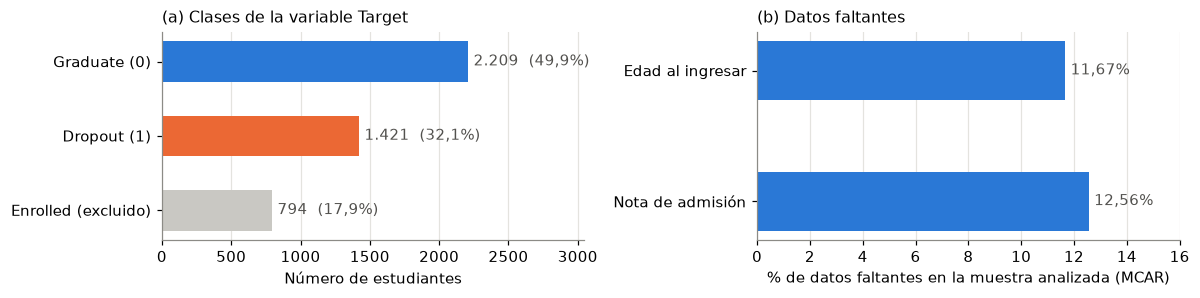

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
conteo = df_completo['Target'].value_counts().reindex(['Graduate', 'Dropout', 'Enrolled'])
ax[0].barh(['Graduate (0)', 'Dropout (1)', 'Enrolled (excluido)'], conteo.values,
           color=[AZUL, NARANJA, '#c9c8c3'], height=0.55)
ax[0].invert_yaxis()
for i, v in enumerate(conteo.values):
    ax[0].text(v + 40, i, f'{coma(v, 0)}  ({coma(v / conteo.sum() * 100)}%)', va='center', color=GRIS)
ax[0].set_xlim(0, conteo.max() * 1.38); ax[0].set_xlabel('Número de estudiantes')
ax[0].set_title('(a) Clases de la variable Target'); ax[0].grid(axis='y', visible=False)

pct = df[['Admission grade', 'Age at enrollment']].isna().mean() * 100
ax[1].barh(['Nota de admisión', 'Edad al ingresar'], pct.values, color=AZUL, height=0.45)
for i, v in enumerate(pct.values):
    ax[1].text(v + 0.2, i, f'{coma(v, 2)}%', va='center', color=GRIS)
ax[1].set_xlim(0, 16); ax[1].set_xlabel('% de datos faltantes en la muestra analizada (MCAR)')
ax[1].set_title('(b) Datos faltantes'); ax[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s1_fig1_objetivo_faltantes.png'); plt.show()

## 2. Análisis exploratorio de datos

### 2.1 Variables numéricas: tendencia central y dispersión (Tabla 2 del informe)

La curtosis se informa en exceso (pandas `kurt()`): vale 0 en una distribución normal; valores positivos indican
colas más pesadas y valores negativos, una distribución más aplanada.

In [9]:
cuant = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
         'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
         'Curricular units 2nd sem (grade) sin ceros', 'Unemployment rate']
desc = pd.DataFrame({
    'n': df[cuant].count(), 'Media': df[cuant].mean(), 'Mediana': df[cuant].median(),
    'Desv. est.': df[cuant].std(), 'CV %': df[cuant].std() / df[cuant].mean() * 100,
    'RIC': df[cuant].quantile(0.75) - df[cuant].quantile(0.25),
    'Mínimo': df[cuant].min(), 'Máximo': df[cuant].max(), 'Asimetría': df[cuant].skew(),
    'Curtosis': df[cuant].kurt()})  # curtosis en exceso (normal = 0)
desc.round(2)

,n,Media,Mediana,Desv. est.,CV %,RIC,Mínimo,Máximo,Asimetría,Curtosis
Age at enrollment,3072,23.61,20.00,7.92,33.55,7.00,17.0,70.00,1.97,3.72
Admission grade,3041,126.91,126.30,14.24,11.22,16.50,95.0,190.00,0.47,0.56
Previous qualification (grade),3478,132.66,133.10,13.07,9.85,15.00,95.0,190.00,0.26,0.89
Curricular units 1st sem (approved),3478,5.00,6.00,3.15,62.90,3.00,0.0,26.00,0.81,3.40
Curricular units 2nd sem (approved),3478,4.72,5.00,3.08,65.38,3.00,0.0,20.00,0.25,0.94
Curricular units 2nd sem (grade) sin ceros,2828,12.88,12.83,1.38,10.69,1.91,10.0,18.57,0.28,-0.13
Unemployment rate,3478,11.63,11.10,2.67,22.96,4.50,7.6,16.20,0.19,-1.00


### Figura 2 - Distribución de las variables numéricas principales

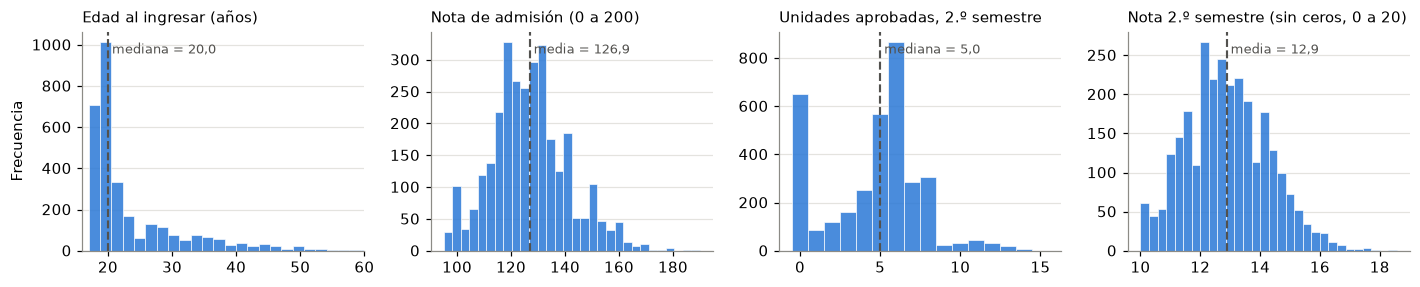

In [10]:
paneles = [('Age at enrollment', 'Edad al ingresar (años)', 'mediana'),
           ('Admission grade', 'Nota de admisión (0 a 200)', 'media'),
           ('Curricular units 2nd sem (approved)', 'Unidades aprobadas, 2.º semestre', 'mediana'),
           ('Curricular units 2nd sem (grade) sin ceros', 'Nota 2.º semestre (sin ceros, 0 a 20)', 'media')]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.7))
for ax, (col, titulo, nombre) in zip(axes, paneles):
    x = df[col].dropna()
    ref = x.median() if nombre == 'mediana' else x.mean()
    bins = np.arange(-0.5, 16.5, 1) if 'approved' in col else 30
    ax.hist(x, bins=bins, color=AZUL, alpha=0.85, edgecolor='white', linewidth=0.5)
    ax.axvline(ref, color=GRIS, ls='--', lw=1.4)
    ax.text(ref, ax.get_ylim()[1] * 0.95, f' {nombre} = {coma(ref)}', color=GRIS, va='top', fontsize=8.5)
    ax.set_title(titulo, fontsize=9.5); ax.grid(axis='x', visible=False)
axes[0].set_xlim(16, 60); axes[0].set_ylabel('Frecuencia')
plt.tight_layout(); plt.savefig(f'{FIG}/s1_fig2_distribuciones.png'); plt.show()

### 2.2 Variables categóricas: frecuencias absolutas y relativas (Tabla 3 del informe)

In [11]:
etiquetas = {'Daytime/evening attendance': ('Jornada', 'Diurna'), 'Tuition fees up to date': ('Matrícula al día', 'Sí'),
             'Displaced': ('Desplazado', 'Sí'), 'Gender': ('Sexo', 'Hombre'), 'Scholarship holder': ('Becado', 'Sí'),
             'Debtor': ('Deudor', 'Sí'), 'International': ('Internacional', 'Sí'),
             'Educational special needs': ('Necesidades educativas especiales', 'Sí')}
frec = pd.DataFrame({'Variable': [etiquetas[c][0] for c in binarias], 'Categoría': [etiquetas[c][1] for c in binarias],
                     'Frecuencia': df[binarias].sum().values, '%': (df[binarias].mean() * 100).round(1).values})
frec = frec.sort_values('%', ascending=False).reset_index(drop=True)
display(frec)

estado = df['Marital status'].map({1: 'Soltero', 2: 'Casado', 3: 'Viudo', 4: 'Divorciado',
                                   5: 'Unión de hecho', 6: 'Separado legalmente'})
display(pd.DataFrame({'Frecuencia': estado.value_counts(), '%': (estado.value_counts(normalize=True) * 100).round(1)}))
orden = df['Application order'].value_counts().sort_index()
pd.DataFrame({'Frecuencia': orden, '%': (orden / n * 100).round(1)}).rename_axis('Orden de preferencia')

,Variable,Categoría,Frecuencia,%
0,Jornada,Diurna,3070,88.3
1,Matrícula al día,Sí,3016,86.7
2,Desplazado,Sí,1870,53.8
3,Sexo,Hombre,1163,33.4
4,Becado,Sí,930,26.7
5,Deudor,Sí,393,11.3
6,Internacional,Sí,80,2.3
7,Necesidades educativas especiales,Sí,36,1.0


,Frecuencia,%
Marital status,,
Soltero,3050,87.7
Casado,324,9.3
Divorciado,75,2.2
Unión de hecho,22,0.6
Separado legalmente,5,0.1
Viudo,2,0.1


,Frecuencia,%
Orden de preferencia,,
0,1,0.0
1,2352,67.6
2,437,12.6
3,237,6.8
4,206,5.9
5,126,3.6
6,119,3.4


### 2.3 Análisis bivariado

In [12]:
# Correlaciones de Pearson (las notas excluyen los ceros; cada par usa los casos disponibles)
cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
        'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
        'Curricular units 1st sem (grade) sin ceros', 'Curricular units 2nd sem (grade) sin ceros',
        'Unemployment rate', 'Inflation rate', 'GDP', OBJETIVO]
cortos = ['Edad', 'Nota admisión', 'Nota previa', 'Aprob. 1.er sem', 'Aprob. 2.º sem',
          'Nota 1.er sem', 'Nota 2.º sem', 'Desempleo', 'Inflación', 'PIB', 'Deserta']
corr = df[cols].corr()
corr[OBJETIVO].drop(OBJETIVO).sort_values().round(3)

Curricular units 2nd sem (approved)          -0.686
Curricular units 1st sem (approved)          -0.581
Curricular units 2nd sem (grade) sin ceros   -0.333
Curricular units 1st sem (grade) sin ceros   -0.328
Admission grade                              -0.124
Previous qualification (grade)               -0.111
GDP                                          -0.045
Unemployment rate                            -0.007
Inflation rate                                0.031
Age at enrollment                             0.286
Name: Deserta, dtype: float64

In [13]:
# Porcentaje de deserción por factor cualitativo, con IC 95 %
factores = [('Tuition fees up to date', 'Matrícula al día', {0: 'No', 1: 'Sí'}),
            ('Debtor', 'Deudor', {0: 'No', 1: 'Sí'}),
            ('Scholarship holder', 'Becado', {0: 'No', 1: 'Sí'}),
            ('Gender', 'Sexo', {0: 'Mujer', 1: 'Hombre'}),
            ('Daytime/evening attendance', 'Jornada', {0: 'Vespertina', 1: 'Diurna'}),
            ('Displaced', 'Desplazado', {0: 'No', 1: 'Sí'})]
filas = []
for col, nombre, mapa_v in factores:
    for v in (1, 0):
        g = df.loc[df[col] == v, OBJETIVO]; p = g.mean(); ee = np.sqrt(p * (1 - p) / len(g))
        filas.append({'Factor': nombre, 'Grupo': mapa_v[v], 'n': len(g), '% deserta': p * 100,
                      'IC inf.': (p - 1.96 * ee) * 100, 'IC sup.': (p + 1.96 * ee) * 100})
tasas = pd.DataFrame(filas)
tasas.round(1)

,Factor,Grupo,n,% deserta,IC inf.,IC sup.
0,Matrícula al día,Sí,3016,30.1,28.5,31.7
1,Matrícula al día,No,462,94.4,92.3,96.5
2,Deudor,Sí,393,75.3,71.1,79.6
3,Deudor,No,3085,34.0,32.3,35.6
4,Becado,Sí,930,13.1,10.9,15.3
5,Becado,No,2548,48.0,46.0,49.9
6,Sexo,Hombre,1163,56.5,53.6,59.3
7,Sexo,Mujer,2315,29.7,27.8,31.5
8,Jornada,Diurna,3070,37.0,35.3,38.7
9,Jornada,Vespertina,408,50.7,45.9,55.6


### Figura 3 - Variables categóricas: frecuencias y relación con la deserción

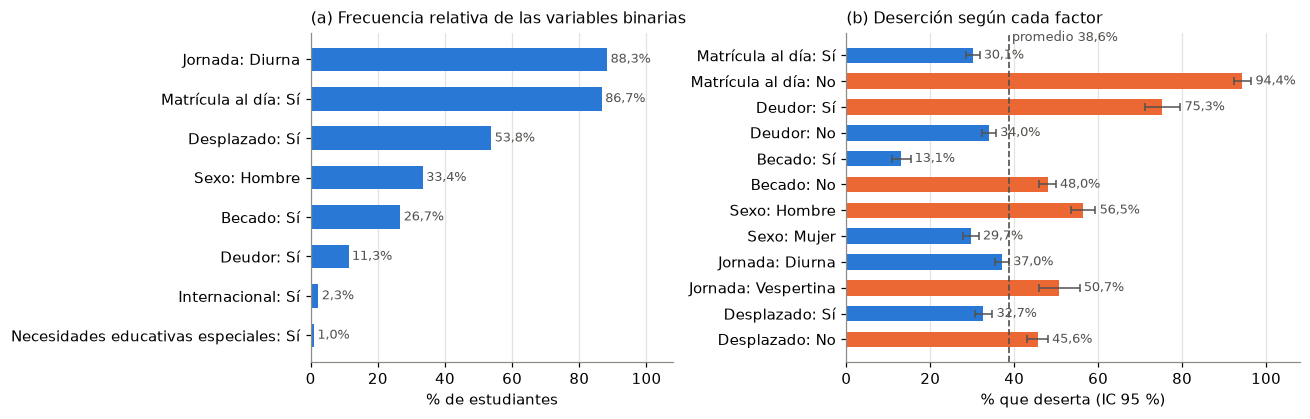

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1, 1.25]})

f = frec.sort_values('%')
ax[0].barh([f'{v}: {c}' for v, c in zip(f['Variable'], f['Categoría'])], f['%'], color=AZUL, height=0.6)
for i, v in enumerate(f['%']):
    ax[0].text(v + 1, i, f'{coma(v)}%', va='center', color=GRIS, fontsize=8.5)
ax[0].set_xlim(0, 108); ax[0].set_xlabel('% de estudiantes'); ax[0].set_title('(a) Frecuencia relativa de las variables binarias')
ax[0].grid(axis='y', visible=False)

y = np.arange(len(tasas))[::-1]
g_pct = df[OBJETIVO].mean() * 100
ax[1].barh(y, tasas['% deserta'], color=[NARANJA if v > g_pct else AZUL for v in tasas['% deserta']], height=0.6)
ax[1].errorbar(tasas['% deserta'], y, xerr=[tasas['% deserta'] - tasas['IC inf.'], tasas['IC sup.'] - tasas['% deserta']],
               fmt='none', ecolor=GRIS, capsize=2.5, lw=1)
for yi, (_, r) in zip(y, tasas.iterrows()):
    ax[1].text(r['IC sup.'] + 1, yi, f"{coma(r['% deserta'])}%", va='center', color=GRIS, fontsize=8.5)
ax[1].set_yticks(y); ax[1].set_yticklabels([f"{r['Factor']}: {r['Grupo']}" for _, r in tasas.iterrows()])
ax[1].axvline(g_pct, color=GRIS, ls='--', lw=1.1)
ax[1].text(g_pct + 0.8, y.max() + 0.55, f'promedio {coma(g_pct)}%', color=GRIS, fontsize=8.5)
ax[1].set_xlim(0, 108); ax[1].set_xlabel('% que deserta (IC 95 %)'); ax[1].set_title('(b) Deserción según cada factor')
ax[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s1_fig3_categoricas.png'); plt.show()

### Figura 4 - Matriz de correlaciones

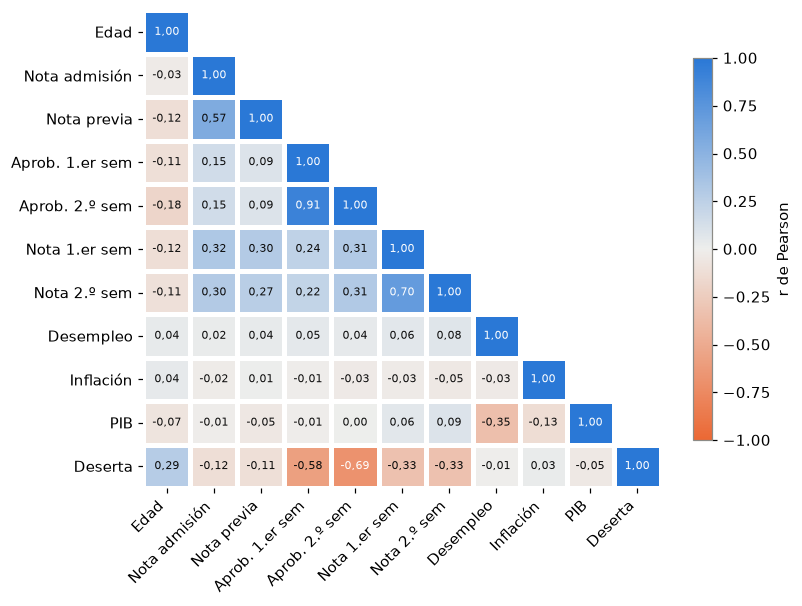

In [15]:
k = len(corr)
oculto = np.triu(np.ones((k, k), dtype=bool), k=1)
mapa = LinearSegmentedColormap.from_list('divergente', [NARANJA, '#eeeeec', AZUL])
fig, ax = plt.subplots(figsize=(7.4, 5.6))
ax.grid(False)
im = ax.pcolormesh(np.ma.masked_array(corr.values, oculto), cmap=mapa, vmin=-1, vmax=1, edgecolors='white', linewidth=2)
ax.invert_yaxis()
for i in range(k):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j + 0.5, i + 0.5, coma(v, 2), ha='center', va='center', fontsize=7,
                color='white' if abs(v) > 0.6 else '#0b0b0b')
ax.set_xticks(np.arange(k) + 0.5); ax.set_xticklabels(cortos, rotation=45, ha='right')
ax.set_yticks(np.arange(k) + 0.5); ax.set_yticklabels(cortos)
for lado in ax.spines.values():
    lado.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='r de Pearson')
plt.tight_layout(); plt.savefig(f'{FIG}/s1_fig4_correlaciones.png'); plt.show()

## 3. Estimación de parámetros

Intervalos al 95 % para cuatro variables numéricas y una proporción:

- **Media:** $\bar{x} \pm t_{0.975,\,n-1}\cdot s/\sqrt{n}$. Se usa *t* de Student porque la desviación estándar
  poblacional es desconocida; con $n > 3.000$ el Teorema Central del Límite respalda la normalidad aproximada de
  la media aunque las variables sean asimétricas.
- **Proporción:** $\hat{p} \pm z_{0.975}\sqrt{\hat{p}(1-\hat{p})/n}$ (aproximación normal; $n\hat{p}$ y
  $n(1-\hat{p})$ mayores que 10).
- **Mediana de la nota de admisión**: *bootstrap* de percentiles, 5.000 remuestras, semilla 42 (la mediana no tiene una fórmula sencilla de error estándar).

**Cómo leer el 95 %.** El nivel de confianza es una propiedad del procedimiento, no de un intervalo en particular:
si se repitiera el muestreo muchas veces, el 95 % de los intervalos construidos de esta forma contendría el
parámetro real. Un intervalo ya calculado lo contiene o no; no hay un 95 % de probabilidad de que el parámetro esté
dentro de él.

In [16]:
def ic_media(x):
    x = pd.Series(x).dropna(); m, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    t = stats.t.ppf(0.975, df=len(x) - 1)
    return m, m - t * ee, m + t * ee, len(x)

def ic_prop(x):
    x = pd.Series(x).dropna(); p = x.mean(); ee = np.sqrt(p * (1 - p) / len(x))
    return p, p - 1.96 * ee, p + 1.96 * ee, len(x)

parametros = [('Edad media al ingresar (años)', ic_media(df['Age at enrollment'])),
              ('Nota de admisión media', ic_media(df['Admission grade'])),
              ('Unidades aprobadas medias, 1.er sem.', ic_media(df['Curricular units 1st sem (approved)'])),
              ('Unidades aprobadas medias, 2.º sem.', ic_media(df['Curricular units 2nd sem (approved)'])),
              ('Proporción que deserta', ic_prop(df[OBJETIVO]))]
tabla_ic = pd.DataFrame([{'Parámetro': p, 'Estimación': r[0], 'IC 95% inf.': r[1], 'IC 95% sup.': r[2],
                          'Amplitud': r[2] - r[1], 'n': r[3]} for p, r in parametros]).set_index('Parámetro')
tabla_ic.round(4)

,Estimación,IC 95% inf.,IC 95% sup.,Amplitud,n
Parámetro,,,,,
Edad media al ingresar (años),23.6130,23.3327,23.8932,0.5605,3072
Nota de admisión media,126.9073,126.4009,127.4136,1.0127,3041
"Unidades aprobadas medias, 1.er sem.",5.0009,4.8963,5.1054,0.2092,3478
"Unidades aprobadas medias, 2.º sem.",4.7159,4.6134,4.8184,0.2050,3478
Proporción que deserta,0.3864,0.3702,0.4026,0.0324,3478


In [17]:
# IC por grupo para las unidades aprobadas (insumo para la interpretación)
for g, nombre in [(1, 'Dropout'), (0, 'Graduate')]:
    m, lo, hi, nn = ic_media(df.loc[df[OBJETIVO] == g, 'Curricular units 2nd sem (approved)'])
    print(f'{nombre:8s}: media = {m:.2f}  IC 95% = [{lo:.2f}; {hi:.2f}]  n = {nn:,}')

# Bootstrap de la mediana de la nota de admisión
rng = np.random.default_rng(SEMILLA)
nota = df['Admission grade'].dropna().to_numpy()
medianas = np.array([np.median(rng.choice(nota, size=len(nota), replace=True)) for _ in range(5000)])
print(f'\nNota de admisión: media = {nota.mean():.2f}, mediana = {np.median(nota):.2f}')
print(f'IC 95% bootstrap de la mediana: [{np.percentile(medianas, 2.5):.2f}; {np.percentile(medianas, 97.5):.2f}]')

Dropout : media = 2.05  IC 95% = [1.91; 2.19]  n = 1,344
Graduate: media = 6.39  IC 95% = [6.31; 6.48]  n = 2,134



Nota de admisión: media = 126.91, mediana = 126.30
IC 95% bootstrap de la mediana: [125.60; 126.80]


## 4. Pruebas de hipótesis

Nivel de significancia $\alpha = 0{,}05$: valor convencional en estudios aplicados que equilibra los errores de
tipo I y II. Como las muestras superan los 3.000 casos, valores *p* muy pequeños son esperables; por eso cada
prueba informa su tamaño del efecto.

### 4.1 Prueba 1: unidades aprobadas en el 2.º semestre, Dropout frente a Graduate
$H_0:\ \mu_{\text{Dropout}} = \mu_{\text{Graduate}}$ vs. $H_1:\ \mu_{\text{Dropout}} \neq \mu_{\text{Graduate}}$

In [18]:
col = 'Curricular units 2nd sem (approved)'
a = df.loc[df[OBJETIVO] == 1, col]; b = df.loc[df[OBJETIVO] == 0, col]

# Supuestos
print('Independencia: cada fila es un estudiante distinto (grupos independientes).')
print(f'Tamaños: Dropout = {len(a):,}, Graduate = {len(b):,} -> TCL aplicable')
print(f'Asimetría: Dropout = {a.skew():.2f}, Graduate = {b.skew():.2f}')
lev = stats.levene(a, b)
print(f'Levene: estadístico = {lev.statistic:.1f}, p = {lev.pvalue:.1e} -> varianzas distintas, se usa Welch\n')

t, p = stats.ttest_ind(a, b, equal_var=False)
sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
d = (a.mean() - b.mean()) / sp
ee = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
gl = ee**4 / ((a.var(ddof=1) / len(a))**2 / (len(a) - 1) + (b.var(ddof=1) / len(b))**2 / (len(b) - 1))
dif = a.mean() - b.mean(); m = stats.t.ppf(0.975, gl) * ee
print(f'Medias: Dropout = {a.mean():.2f} (desv. {a.std():.2f}), Graduate = {b.mean():.2f} (desv. {b.std():.2f})')
print(f'Diferencia = {dif:.2f}  IC 95% = [{dif - m:.2f}; {dif + m:.2f}]')
print(f"t de Welch = {t:.2f}  gl = {gl:.0f}  p {'< 0.0001' if p < 1e-4 else f'= {p:.4f}'}  d de Cohen = {d:.2f}")

# Verificación de robustez: prueba no paramétrica de Mann-Whitney
u = stats.mannwhitneyu(a, b, alternative='two-sided')
print(f"Mann-Whitney (robustez): U = {u.statistic:,.0f}, p {'< 0.0001' if u.pvalue < 1e-4 else f'= {u.pvalue:.4f}'}")
print(f'Medianas: Dropout = {a.median():.0f}, Graduate = {b.median():.0f}')
print('Decisión:', 'se rechaza H0' if p < ALFA else 'no se rechaza H0')

Independencia: cada fila es un estudiante distinto (grupos independientes).
Tamaños: Dropout = 1,344, Graduate = 2,134 -> TCL aplicable
Asimetría: Dropout = 1.39, Graduate = 2.28
Levene: estadístico = 179.7, p = 5.6e-40 -> varianzas distintas, se usa Welch

Medias: Dropout = 2.05 (desv. 2.60), Graduate = 6.39 (desv. 1.98)
Diferencia = -4.34  IC 95% = [-4.51; -4.18]
t de Welch = -52.33  gl = 2311  p < 0.0001  d de Cohen = -1.94
Mann-Whitney (robustez): U = 259,802, p < 0.0001
Medianas: Dropout = 1, Graduate = 6
Decisión: se rechaza H0


### 4.2 Prueba 2: matrícula al día y deserción (prueba *z* de dos proporciones)

$H_0:\ p_{\text{atrasada}} = p_{\text{al día}}$ vs. $H_1:\ p_{\text{atrasada}} \neq p_{\text{al día}}$, con
$z = (\hat p_1-\hat p_0)\big/\sqrt{\hat p(1-\hat p)(1/n_1+1/n_0)}$ y $\hat p$ la proporción combinada (el mismo
procedimiento del ejemplo del curso). Advertencia: el pago atrasado puede ser consecuencia de la decisión de abandonar.

In [19]:
g1 = df.loc[df['Tuition fees up to date'] == 0, OBJETIVO]      # matrícula atrasada
g0 = df.loc[df['Tuition fees up to date'] == 1, OBJETIVO]      # matrícula al día
p1, p0, n1, n0 = g1.mean(), g0.mean(), len(g1), len(g0)
print(f'Supuesto (n·p y n·(1-p) >= 10): {min(n1*p1, n1*(1-p1), n0*p0, n0*(1-p0)):.0f}')
pc = (g1.sum() + g0.sum()) / (n1 + n0)
z = (p1 - p0) / np.sqrt(pc * (1 - pc) * (1 / n1 + 1 / n0))
p_z = 2 * stats.norm.sf(abs(z))
ee = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(f'Deserción: atrasada = {p1*100:.1f}% (n = {n1:,}), al día = {p0*100:.1f}% (n = {n0:,})')
print(f'Diferencia = {(p1-p0)*100:.1f} pp  IC 95% = [{(p1-p0-1.96*ee)*100:.1f}; {(p1-p0+1.96*ee)*100:.1f}]')
print(f"z = {z:.2f}  p {'< 0.0001' if p_z < 1e-4 else f'= {p_z:.4f}'}  riesgo relativo = {p1/p0:.2f}")
print('Decisión:', 'se rechaza H0' if p_z < ALFA else 'no se rechaza H0')

Supuesto (n·p y n·(1-p) >= 10): 26
Deserción: atrasada = 94.4% (n = 462), al día = 30.1% (n = 3,016)
Diferencia = 64.3 pp  IC 95% = [61.6; 66.9]
z = 26.42  p < 0.0001  riesgo relativo = 3.13
Decisión: se rechaza H0


### 4.3 Prueba 3: beca y deserción
$H_0$: tener beca y desertar son independientes vs. $H_1$: están asociados. Ambas variables son cualitativas:
prueba $\chi^2$ de independencia sobre la tabla de 2 × 2.

In [20]:
tabla = pd.crosstab(df['Scholarship holder'].map({0: 'Sin beca', 1: 'Con beca'}), df[OBJETIVO])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
tasa = tabla[1] / tabla.sum(axis=1) * 100
odds = (tabla.loc['Sin beca', 1] / tabla.loc['Sin beca', 0]) / (tabla.loc['Con beca', 1] / tabla.loc['Con beca', 0])
print(tabla, '\n')
print(f'Supuesto: frecuencia esperada mínima = {esperadas.min():.0f} (>= 5)')
print(f"% que deserta: con beca = {tasa['Con beca']:.1f}%, sin beca = {tasa['Sin beca']:.1f}%")
print(f"Chi² = {chi2:.2f}  gl = {gl}  p {'< 0.0001' if p < 1e-4 else f'= {p:.4f}'}  V de Cramér = {v:.3f}")
print(f"Riesgo relativo = {tasa['Sin beca'] / tasa['Con beca']:.2f}   Razón de momios = {odds:.2f}")
print('Decisión:', 'se rechaza H0' if p < ALFA else 'no se rechaza H0')

Deserta                0     1
Scholarship holder            
Con beca             808   122
Sin beca            1326  1222 

Supuesto: frecuencia esperada mínima = 359 (>= 5)
% que deserta: con beca = 13.1%, sin beca = 48.0%
Chi² = 348.82  gl = 1  p < 0.0001  V de Cramér = 0.317
Riesgo relativo = 3.66   Razón de momios = 6.10
Decisión: se rechaza H0


### 4.4 Comprobación MCAR y error tipo I demostrado
Se contrasta con $\chi^2$ si el faltante de cada variable es independiente de `Target`. Como los faltantes se
generaron al azar, $H_0$ es **verdadera por construcción**: cualquier rechazo es un error tipo I. Para mostrarlo, la
generación se repite con 1.000 semillas distintas y se cuenta cuántas veces el $\chi^2$ da $p < 0{,}05$.

In [21]:
for var in ['Admission grade', 'Age at enrollment']:
    est, p_var, _, _ = stats.chi2_contingency(pd.crosstab(df_completo[var].isna(), df_completo['Target']))
    print(f'{var:18s}: Chi² = {est:.2f}  p = {p_var:.3f}')
print('Con dos pruebas, umbral de Bonferroni = 0,025\n')

objetivo3 = df_completo['Target']
n_total = len(objetivo3); n_borrar = int(round(0.12 * n_total))
p_sim = []
for semilla in range(1000):
    marca = np.zeros(n_total, dtype=bool)
    marca[np.random.default_rng(semilla).choice(n_total, size=n_borrar, replace=False)] = True
    p_sim.append(stats.chi2_contingency(pd.crosstab(marca, objetivo3))[1])
p_sim = np.array(p_sim)
print(f'Simulación con 1.000 semillas: {np.mean(p_sim < 0.05) * 100:.1f}% de los χ² da p < 0,05 (nivel nominal: 5%)')

Admission grade   : Chi² = 6.40  p = 0.041
Age at enrollment : Chi² = 2.88  p = 0.237
Con dos pruebas, umbral de Bonferroni = 0,025



Simulación con 1.000 semillas: 5.6% de los χ² da p < 0,05 (nivel nominal: 5%)


### Figura 5 - Resultados de las pruebas de hipótesis

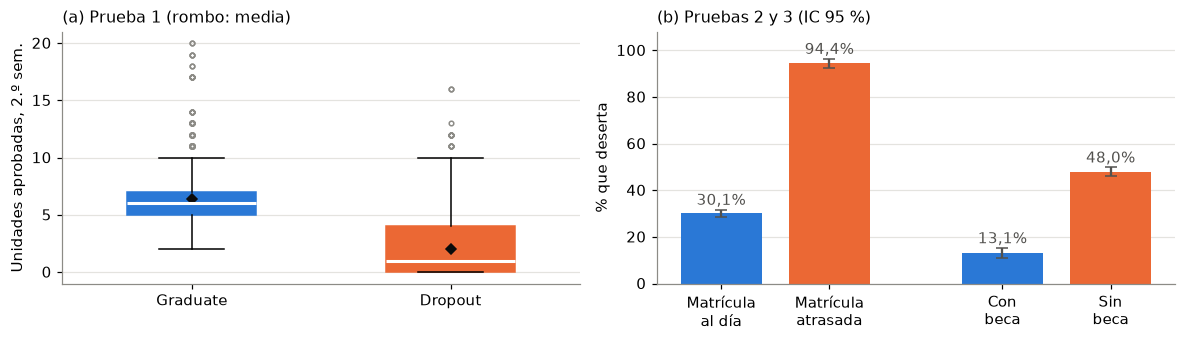

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
cajas = ax[0].boxplot([b, a], patch_artist=True, widths=0.5,
                      medianprops=dict(color='white', linewidth=2),
                      flierprops=dict(marker='o', markersize=3, markerfacecolor='none', markeredgecolor='#8c8b86'))
for caja, color in zip(cajas['boxes'], [AZUL, NARANJA]):
    caja.set_facecolor(color); caja.set_edgecolor(color)
ax[0].plot([1, 2], [b.mean(), a.mean()], 'D', color='#0b0b0b', markersize=5)
ax[0].set_xticks([1, 2]); ax[0].set_xticklabels(['Graduate', 'Dropout'])
ax[0].set_ylabel('Unidades aprobadas, 2.º sem.'); ax[0].set_title('(a) Prueba 1 (rombo: media)')
ax[0].grid(axis='x', visible=False)

grupos = [('Matrícula\nal día', p0, n0, AZUL), ('Matrícula\natrasada', p1, n1, NARANJA),
          ('Con\nbeca', tasa['Con beca'] / 100, tabla.loc['Con beca'].sum(), AZUL),
          ('Sin\nbeca', tasa['Sin beca'] / 100, tabla.loc['Sin beca'].sum(), NARANJA)]
xs = [0, 1, 2.6, 3.6]
for x, (nombre, pp, nn, color) in zip(xs, grupos):
    e = 1.96 * np.sqrt(pp * (1 - pp) / nn) * 100
    ax[1].bar(x, pp * 100, color=color, width=0.75, yerr=e, capsize=4, ecolor=GRIS)
    ax[1].text(x, pp * 100 + e + 2, f'{coma(pp * 100)}%', ha='center', color=GRIS)
ax[1].set_xticks(xs); ax[1].set_xticklabels([g[0] for g in grupos])
ax[1].set_ylim(0, 108); ax[1].set_ylabel('% que deserta'); ax[1].set_title('(b) Pruebas 2 y 3 (IC 95 %)')
ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig(f'{FIG}/s1_fig5_pruebas.png'); plt.show()

## 5. Resumen

- Calidad: sin duplicados; se excluyen los estudiantes sin actividad académica registrada; faltantes MCAR en dos
  variables; notas 0 = sin unidades aprobadas.
- Las unidades aprobadas son la variable más asociada a la deserción.
- Prueba 1: los desertores aprueban muchas menos unidades en el 2.º semestre; efecto muy grande.
- Prueba 2: la matrícula atrasada concentra la mayor diferencia de proporciones (z de dos proporciones).
- Prueba 3: sin beca, el riesgo de desertar se multiplica; asociación moderada.
- El χ² de comprobación MCAR da p < 0,05 aunque H0 es verdadera: error tipo I con la frecuencia nominal.
- Próximos pasos (Sumativa 2 y 3): imputación, simulación y remuestreo, regresión logística atenta a la
  multicolinealidad entre las unidades aprobadas de ambos semestres.